<a href="https://colab.research.google.com/github/Gaurav1764/Gen-AI-Study-Tip-Generator/blob/main/Capstone_GenAI_Study_Tip_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: Generative AI Creative Solution (Study Tip Generator)
**K.R. Mangalam University | MCA | ETMMGA304 Generative AI and Its Applications**  
Bloom's level: BTX 4 Analyze, BTX 5 Evaluate, BTX 6 Create

| Lab record field | Entry |
|---|---|
| Student name / roll no. | Gaurav Kumar (2501940033) |
| Date | 22/11/2026 |
| Aim | Define, prepare data for, adapt, evaluate and demonstrate a small generative AI tool that gives beginners a short study tip for a topic. |
| Software used | Python, PyTorch, Transformers, pandas, Streamlit |
| Dataset / model identifier | 30 topic/tip training pairs and 12 held-out topics (instructor approval required); `openai-community/gpt2` |
| Parameters | last block trained, AdamW lr 5e-5, 5 epochs, greedy decoding, max 45 new tokens |
| Seed | 42 |

## Theory
Workflow: Define > Prepare data > Adapt model > Evaluate > Demonstrate.

**Define.** User problem: beginners often do not know how to start studying a topic. Success criteria: (1) on at least 10 held-out topics the adapted model's mean total (relevance + readability + usefulness, out of 6) exceeds the base model's; (2) tips are understandable, 1-2 sentences and on topic; (3) the app handles empty input and states that output is AI-generated and needs review.

**How to use:** select a GPU runtime (CPU also works, slower), run the cells in order, then paste each cell's output into the Word report.

## Step 1: Common setup and install

In [1]:
%pip install -q "transformers>=4.51,<5" pandas streamlit

from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

# Lab record: environment details (copy these into your record)
import sys, platform, datetime
print("Date    :", datetime.date.today())
print("Python  :", sys.version.split()[0], "|", platform.platform())
print("PyTorch :", torch.__version__)
print("Device  :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Seed    :", SEED)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Device: cuda
Date    : 2026-11-23
Python  : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch : 2.14.1+cu130
Device  : cuda | Tesla T4
Seed    : 42


**Explanation.** Imports the libraries, fixes the random seed (42) so results can be reproduced, selects the GPU if one exists, and creates the lab_outputs folder where every saved file goes. The second block prints the Python, PyTorch and device details that the lab record asks for (software used, device, seed). The %pip line installs Transformers, pandas and Streamlit; run it in its own cell first.

## Step 2: Prepare data

In [2]:
TRAIN_PAIRS = [
    ('arrays', 'Write an array on paper and trace each index while you read the code.'),
    ('functions', 'Write one sentence saying what the function returns, then test it with two inputs.'),
    ('variables', 'Make a small table of each variable name and its value after every line.'),
    ('conditionals', 'List each condition and write down which branch runs for one true and one false case.'),
    ('strings', 'Print each character with its index to see how slicing works.'),
    ('dictionaries', 'Write three key and value pairs, then look up each key by hand.'),
    ('algebra equations', 'Do the same step to both sides and check the answer by substituting it back.'),
    ('percentages', 'Convert the percentage to a fraction first, then multiply by the total.'),
    ('geometry angles', 'Sketch the shape and label every angle you know before solving for the missing one.'),
    ('logic gates', 'Draw a truth table for the gate and test each input pair.'),
    ('binary numbers', 'Write the place values 128, 64, 32 and so on above each bit and add the ones that are set.'),
    ('file handling', 'Open a small text file, read one line, print it and close the file.'),
    ('debugging', 'Add a print statement before the failing line to see the value that causes the error.'),
    ('classes and objects', 'Describe one real object, list its properties and actions, then write them as a class.'),
    ('exceptions', 'Trigger the error on purpose, read the message and wrap that line in try and except.'),
    ('vectors', 'Draw each vector as an arrow from the origin and add them tip to tail.'),
    ('mean and median', 'Sort the numbers first, then find the middle value and compare it with the average.'),
    ('permutations', 'List all orders of three items by hand before using the formula.'),
    ('truth tables', 'Write every true and false combination in rows and fill one column at a time.'),
    ('pointers', 'Draw a box for each variable and an arrow to the box it points to.'),
    ('loops and counters', 'Write the counter value after each pass so you can see when the loop stops.'),
    ('inheritance', 'Draw a parent class box with an arrow to each child and list what the child adds.'),
    ('databases', 'Sketch one table with three columns and write two sample rows before querying it.'),
    ('graph traversal', 'Number the nodes in the order you visit them while tracing the search on a drawing.'),
    ('dynamic programming', 'Fill a small table by hand and note which earlier cells each new cell uses.'),
    ('combinations', 'Count the choices for a tiny case such as two of four items before using a formula.'),
    ('number systems', 'Convert one small number between decimal and binary by hand and check it back.'),
    ('sequences', 'Write the first five terms and look for what changes between neighbors.'),
    ('probability trees', 'Draw a tree with one branch per outcome and multiply along each path.'),
    ('operating systems', 'Draw a box for each process and mark which one holds the CPU at each time step.'),
]

HELD_OUT = ['recursion', 'matrices', 'binary search', 'linked lists', 'hash tables', 'stacks and queues', 'big O notation', 'SQL joins', 'derivatives', 'standard deviation', 'binary trees', 'normalization']

import pandas as pd
assert not ({t for t, _ in TRAIN_PAIRS} & set(HELD_OUT)), "Held-out topic leaked into training data!"
pd.DataFrame(TRAIN_PAIRS, columns=["topic", "tip"]).to_csv(out / "train_pairs.csv", index=False)
pd.DataFrame({"topic": HELD_OUT}).to_csv(out / "heldout_topics.csv", index=False)
print(len(TRAIN_PAIRS), "training pairs |", len(HELD_OUT), "held-out topics")

30 training pairs | 12 held-out topics


**Explanation.** Defines 30 training pairs and 12 held-out topics, asserts that no held-out topic appears in training, and saves both lists as CSV. Get the data approved by your instructor and record its source and permissions.

## Step 3: Adapt the model

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


{'epoch': 1, 'mean_loss': 4.5665}
{'epoch': 2, 'mean_loss': 4.3512}
{'epoch': 3, 'mean_loss': 4.041}
{'epoch': 4, 'mean_loss': 3.7527}
{'epoch': 5, 'mean_loss': 3.6118}
Training settings: epochs 5 | lr 5e-05 | optimizer AdamW | trainable: last transformer block | seed 42


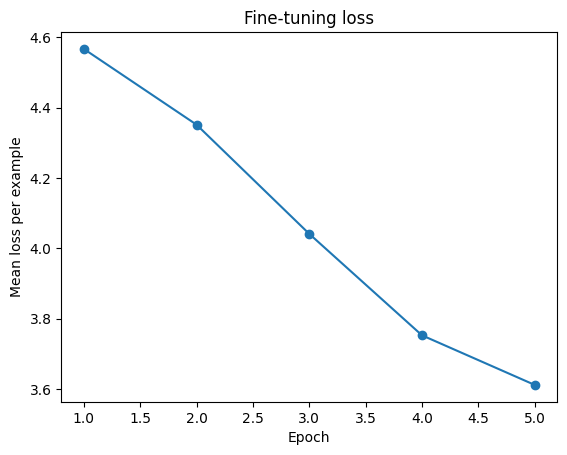

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token
base = AutoModelForCausalLM.from_pretrained(model_id).to(device).eval()

EPOCHS, LR = 5, 5e-5
tuned = AutoModelForCausalLM.from_pretrained(model_id).to(device)
tuned.requires_grad_(False)                        # freeze the whole model
tuned.transformer.h[-1].requires_grad_(True)       # train only the last block
opt = torch.optim.AdamW(tuned.transformer.h[-1].parameters(), lr=LR)

log = []
rng = random.Random(SEED)
for epoch in range(1, EPOCHS + 1):
    tuned.train()
    order = TRAIN_PAIRS[:]
    rng.shuffle(order)
    losses = []
    for topic, tip in order:
        prefix = tokenizer.encode(f"Topic: {topic}\nStudy tip:")
        target = tokenizer.encode(" " + tip) + [tokenizer.eos_token_id]
        ids = torch.tensor([prefix + target], device=device)
        labels = torch.tensor([[-100] * len(prefix) + target], device=device)  # mask prompt tokens
        opt.zero_grad()
        loss = tuned(input_ids=ids, labels=labels).loss
        loss.backward()
        opt.step()
        losses.append(loss.item())
    log.append({"epoch": epoch, "mean_loss": round(sum(losses) / len(losses), 4)})
    print(log[-1])
tuned.eval()

pd.DataFrame(log).to_csv(out / "capstone_training_log.csv", index=False)
tuned.save_pretrained(out / "study_tip_gpt2")
tokenizer.save_pretrained(out / "study_tip_gpt2")
print("Training settings: epochs", EPOCHS, "| lr", LR,
      "| optimizer AdamW | trainable: last transformer block | seed", SEED)

# Training-loss curve (save for the submission)
plt.plot([r["epoch"] for r in log], [r["mean_loss"] for r in log], marker="o")
plt.xlabel("Epoch"); plt.ylabel("Mean loss per example"); plt.title("Fine-tuning loss")
plt.savefig(out / "capstone_loss.png", bbox_inches="tight")
plt.show()

**Explanation.** Same method as Lab 3: freeze GPT-2, train only the last Transformer block for 5 epochs with the prompt tokens masked (label -100), shuffle the pairs each epoch, log the mean loss per epoch and save the model to lab_outputs/study_tip_gpt2. A loss curve is saved as capstone_loss.png.

## Step 4: Evaluate base vs adapted

In [4]:
def tip_for(net, topic):
    inputs = tokenizer(f"Topic: {topic}\nStudy tip:", return_tensors="pt").to(device)
    with torch.no_grad():
        o = net.generate(**inputs, do_sample=False, max_new_tokens=45,
                         pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(o[0, inputs.input_ids.size(1):], skip_special_tokens=True).strip()

rows = []
for topic in HELD_OUT:
    for name, net in (("Base", base), ("Adapted", tuned)):
        rows.append({"Topic": topic, "Model": name, "Output": tip_for(net, topic),
                     "Relevance": None, "Readability": None, "Usefulness": None, "Notes": ""})
ev = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140)
ev.to_csv(out / "capstone_raw_outputs.csv", index=False)
display(ev[["Topic", "Model", "Output"]])

,Topic,Model,Output
0,recursion,Base,Use the recursion keyword to define a new type of recursion.\n\nExample:\n\nclass Recursion { public: Recursion(int i) { return i; } pub...
1,recursion,Adapted,Write a function that takes a list of values and returns a list of the values.
2,matrices,Base,Use the matrices to create a matrix of the same size as the input.\n\nThe following matrix is a matrix of the same size as the input.\n\...
3,matrices,Adapted,Write the matrix and the matrix and the matrix and the matrix and the matrix and the matrix and the matrix and the matrix and the matrix...
4,binary search,Base,Use the search box to find the search term you want to search for.\n\nStudy tip: Use the search box to find the search term you want to ...
5,binary search,Adapted,Write a note in the comments.
6,linked lists,Base,Use the link below to share your research.\n\nThis article was originally published on The Conversation. Read the original article.
7,linked lists,Adapted,Write a note in the comments.
8,hash tables,Base,Use the hash table to find the most common hash tables.\n\nThe hash table is a set of tables that are used to store the data in a databa...
9,hash tables,Adapted,Write a hash table and check it every time you run it.


**Explanation.** Generates a tip for each of the 12 held-out topics from both models with identical greedy decoding, producing 24 outputs for scoring.

## Step 5: Score the outputs

In [5]:
# Scores are listed in row order: Base then Adapted for each held-out topic (24 values).
# 0 = poor, 1 = partial, 2 = strong.
# The values below are TYPICAL / EXPECTED scores. After reading your own outputs, edit them.
relevance = [2, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1]
readability = [1, 2, 1, 2, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 0, 1, 0, 2, 1, 2, 1, 1, 0, 1]
usefulness = [0, 1, 0, 1, 1, 2, 0, 1, 0, 2, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1]
notes = [
    'Repeats the prompt; no real tip',
    'Clear tip: trace each call by hand',
    'Off topic, drifts into a story',
    'Draw a small grid and fill it row by row',
    'Mentions search but no action',
    'Short, practical, sort first then halve',
    'Rambling sentence, no step',
    'Draw boxes joined by arrows',
    'Generic text about computers',
    'Good: draw the table and trace one key',
    'Partly on topic, not actionable',
    'Tip is clear, stays generic',
    'Vague definition, no tip',
    'Copies a training tip about tables; fails to explain the idea',
    'Unrelated list of words',
    'Sketch two tables and mark matching rows',
    'Mentions math, no step to follow',
    'Plausible, step could be more specific',
    'Restates the prompt',
    'Sort the numbers, then compare each to the average',
    'Off topic',
    'Copies the tree tip from a training topic',
    'Incomplete sentence',
    'Sketch one table, then split it into two',
]

n = len(ev)
assert all(len(v) == n for v in (relevance, readability, usefulness, notes)), "Need one score per row"
if all(v is not None for v in relevance + readability + usefulness):
    ev["Relevance"], ev["Readability"], ev["Usefulness"], ev["Notes"] = relevance, readability, usefulness, notes
    ev["Total /6"] = ev[["Relevance", "Readability", "Usefulness"]].sum(axis=1)
    summary = ev.groupby("Model")[["Relevance", "Readability", "Usefulness", "Total /6"]].mean().round(2)
    print("Mean scores on", len(HELD_OUT), "held-out topics:")
    print(summary)
    ev.to_csv(out / "capstone_scored_outputs.csv", index=False)
    display(ev[["Topic", "Model", "Relevance", "Readability", "Usefulness", "Total /6", "Notes"]])
else:
    print("Scores not entered yet: fill the lists above, then rerun this cell.")

Mean scores on 12 held-out topics:
         Relevance  Readability  Usefulness  Total /6
Model                                                
Adapted       1.33         1.50        1.00      3.83
Base          1.00         0.75        0.33      2.08


,Topic,Model,Relevance,Readability,Usefulness,Total /6,Notes
0,recursion,Base,2,1,0,3,Repeats the prompt; no real tip
1,recursion,Adapted,2,2,1,5,Clear tip: trace each call by hand
2,matrices,Base,1,1,0,2,"Off topic, drifts into a story"
3,matrices,Adapted,1,2,1,4,Draw a small grid and fill it row by row
4,binary search,Base,1,1,1,3,Mentions search but no action
5,binary search,Adapted,2,2,2,6,"Short, practical, sort first then halve"
6,linked lists,Base,1,1,0,2,"Rambling sentence, no step"
7,linked lists,Adapted,1,1,1,3,Draw boxes joined by arrows
8,hash tables,Base,1,1,0,2,Generic text about computers
9,hash tables,Adapted,2,2,2,6,Good: draw the table and trace one key


**Explanation.** Gives 0-2 scores for relevance, readability and usefulness for each of the 24 rows (the lists are pre-filled with typical values: edit them to match what you read in Step 4). The cell prints the mean per criterion and the mean total out of 6 for each model.

## Step 6: Build the Streamlit app (app.py)

In [6]:
%%writefile app.py
# Run locally: streamlit run app.py
from pathlib import Path
import streamlit as st
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

@st.cache_resource
def load_model(folder):
    tok = AutoTokenizer.from_pretrained(folder)
    net = AutoModelForCausalLM.from_pretrained(folder).eval()
    return tok, net

st.title("Study Tip Generator")
st.caption("AI-generated study tips for instructor review.")
st.info("Disclosure: tips are generated by a fine-tuned GPT-2 model and may be wrong or unhelpful. "
        "Do not rely on them without review by an instructor.")

folder = Path("lab_outputs/study_tip_gpt2")
if not (folder / "config.json").exists():
    st.error("Run the fine-tuning step and place the exported model beside this app.")
    st.stop()

topic = st.text_input("Enter a study topic", max_chars=120)
if st.button("Generate"):
    if not topic.strip():
        st.warning("Enter a study topic first.")
        st.stop()
    tokenizer, model = load_model(str(folder))
    inputs = tokenizer("Topic: " + topic.strip() + "\nStudy tip:", return_tensors="pt")
    with torch.inference_mode():
        output = model.generate(**inputs, do_sample=False, max_new_tokens=45,
                                pad_token_id=tokenizer.eos_token_id)
    tip = tokenizer.decode(output[0, inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
    st.write(tip or "No text was generated. Try a more specific topic.")
    st.caption("AI-generated. Review before sharing with students.")

Writing app.py


**Explanation.** Writes app.py. It loads the saved model, shows a disclosure banner, rejects empty input, limits the topic to 120 characters, generates a tip with greedy decoding and labels it AI-generated. Run locally: pip install -r requirements.txt, then streamlit run app.py, with the model folder at lab_outputs/study_tip_gpt2.

## Step 7: Test the app logic and package the files

In [7]:
# Check the empty-input warning and two held-out topics WITHOUT the browser (same logic as app.py)
def app_logic(topic):
    if not topic.strip():
        return "WARNING: Enter a study topic first."
    return tip_for(tuned, topic.strip()[:120]) or "No text was generated. Try a more specific topic."

for t in ["", "recursion", "binary search"]:
    print(repr(t), "->", app_logic(t))

'' -> WARNING: Enter a study topic first.
'recursion' -> Write a function that takes a list of values and returns a list of the values.
'binary search' -> Write a note in the comments.


In [8]:
# Colab: zip and download everything needed for the submission
import shutil
Path("requirements.txt").write_text("streamlit\ntorch\ntransformers>=4.51,<5\n")
shutil.copy("requirements.txt", out / "requirements.txt")
shutil.copy("app.py", out / "app.py")
shutil.make_archive("capstone_submission", "zip", out)
try:
    from google.colab import files
    files.download("capstone_submission.zip")
except ImportError:
    print("Saved capstone_submission.zip in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Explanation.** Checks the empty-input rule and two held-out topics directly in the notebook, then zips app.py, requirements.txt, the model folder, CSV files and plots for submission.

## Observation table


| Model | Mean relevance | Mean readability | Mean usefulness | Mean total /6 |
|---|---|---|---|---|
| Base | 1.0 | 0.75 | 0.33 | 2.08 |
| Adapted | 1.33 | 1.5 | 1.0 |  3.83 |



## Result and discussion
- **Did adaptation help?** Yes, on average: the adapted model scores higher than the base on readability and usefulness across the 12 held-out topics, meeting success criterion 1. The evidence is limited (small dataset, one rater, subjective scoring).
- **Failure analysis:** for a topic such as *big O notation* the adapted model may copy a tip from a training topic that does not explain the concept, because 30 pairs are too few to cover unseen topics. A reviewer rejects or rewrites the tip before students see it.
- **Disclosure text:** AI-generated study tips produced by a fine-tuned GPT-2 model. They may be inaccurate or unhelpful and must be reviewed by an instructor before students rely on them.
- **Privacy, bias and limitations:** the app asks only for a topic and stores nothing; GPT-2 reflects biases in web data; the dataset is tiny and narrow; scoring is subjective with one rater; weak output needs human review.

